# Langkah 4 Anggota A — Preprocessing Audio RAVDESS

**Tujuan:** menyiapkan audio agar siap diekstrak fiturnya di langkah 5, dengan aturan yang sama untuk semua file dan bisa diulang persis.

**Urutan preprocessing**

1. Muat audio dan ubah ke **mono** (termasuk 5 file stereo dari langkah 1)
2. **Resample** dari 48 kHz ke 16 kHz
3. **Trim hening** di awal dan akhir (`top_db=30`), karena EDA menunjukkan separuh isi file adalah hening
4. **Normalisasi amplitudo** sebagai pilihan: `'none'` (tanpa normalisasi) atau `'peak'` (puncak diskalakan ke 0,99). Keduanya akan dibandingkan Anggota B di baseline

**Input dan output**

| Jenis | Lokasi (di `MyDrive/project07/`) | Keterangan |
| --- | --- | --- |
| Input | `data/metadata.csv` | Dari langkah 1 |
| Input | `data/raw/ravdess_speech/` | Audio asli 48 kHz, tidak diubah |
| Input (opsional) | `data/eda_audio_stats.csv` | Dari langkah 3, untuk verifikasi silang |
| Output | `src/preprocess.py` | Modul preprocessing; dipakai lagi di langkah 5 dan demo |
| Output | `config.json` | Parameter preprocessing (bagian `preprocessing`) |
| Output | `data/processed/ravdess_16k_trim/` | 1.440 WAV mono 16 kHz hasil trim, **tanpa normalisasi**, format float32 |
| Output | `data/preprocess_log.csv` | Catatan per file: batas trim, durasi, puncak, energi, faktor normalisasi |
| Output | `figures/preprocess/` | 3 grafik + `preprocess_summary.txt` |
| Output | `docs/README_langkah4_preprocessing.md` | Dokumentasi standar langkah ini |

**Mengapa audio hanya disimpan satu versi?** Ambang trim dihitung relatif terhadap bagian terkeras file, jadi hasil trim tidak berubah jika volume dikalikan berapa pun. Normalisasi puncak hanyalah perkalian dengan satu angka, sehingga bisa dilakukan saat ekstraksi fitur. Sel 4 membuktikan sifat ini pada data asli.

**Prasyarat:** langkah 1 selesai. **Perkiraan waktu:** 10–20 menit (Sel 5 paling lama).

**Cara pakai:** jalankan sel berurutan dengan `Shift + Enter`, dan baca penjelasan di atas setiap sel.

## Sel 1 — Persiapan dan cek prasyarat

Menghubungkan Drive, menentukan semua lokasi folder, dan memastikan file dari langkah sebelumnya ada. Jika ada prasyarat yang hilang, sel ini berhenti dengan pesan yang jelas.

In [1]:
import os
import sys
import json
import hashlib
import random
from datetime import datetime

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/project07'
except ImportError:
    BASE_DIR = os.path.abspath('project07')

DATA_DIR = os.path.join(BASE_DIR, 'data')
RAW_DIR = os.path.join(DATA_DIR, 'raw', 'ravdess_speech')
PROC_DIR = os.path.join(DATA_DIR, 'processed', 'ravdess_16k_trim')
SRC_DIR = os.path.join(BASE_DIR, 'src')
FIG_DIR = os.path.join(BASE_DIR, 'figures', 'preprocess')
DOC_DIR = os.path.join(BASE_DIR, 'docs')
CONFIG_PATH = os.path.join(BASE_DIR, 'config.json')
LOG_PATH = os.path.join(DATA_DIR, 'preprocess_log.csv')
MODULE_PATH = os.path.join(SRC_DIR, 'preprocess.py')
for d in [PROC_DIR, SRC_DIR, FIG_DIR, DOC_DIR]:
    os.makedirs(d, exist_ok=True)

wajib = {'metadata.csv': os.path.join(DATA_DIR, 'metadata.csv'),
         'folder audio asli': RAW_DIR}
hilang = [k for k, p in wajib.items() if not os.path.exists(p)]
if hilang:
    raise FileNotFoundError(f'Prasyarat tidak ditemukan: {hilang}. Jalankan langkah 1 dulu.')

meta = pd.read_csv(os.path.join(DATA_DIR, 'metadata.csv'))
EMOSI = ['neutral', 'calm', 'happy', 'sad', 'angry', 'fearful', 'disgust', 'surprised']
BIRU, ORANYE = '#2a78d6', '#eb6834'
TEKS, TEKS2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.edgecolor': TEKS2, 'axes.labelcolor': TEKS, 'text.color': TEKS,
    'xtick.color': TEKS2, 'ytick.color': TEKS2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
})

print('Prasyarat lengkap.')
print('Jumlah file di metadata :', len(meta))
print('Folder hasil            :', PROC_DIR)

Mounted at /content/drive
Prasyarat lengkap.
Jumlah file di metadata : 1440
Folder hasil            : /content/drive/MyDrive/project07/data/processed/ravdess_16k_trim


## Sel 2 — Parameter preprocessing dan `config.json`

Semua parameter ditulis di satu tempat dan disimpan ke `config.json` (bagian `preprocessing`). File ini dipakai bersama seluruh kelompok; sel ini hanya mengubah bagian `preprocessing` dan membiarkan bagian lain.

| Parameter | Nilai | Alasan |
| --- | --- | --- |
| `target_sr` | 16000 Hz | Rentang frekuensi suara bicara tetap tercakup; komputasi jauh lebih ringan daripada 48 kHz |
| `mono` | True | Fitur dihitung dari satu channel; 5 file stereo terbukti identik kiri-kanan |
| `trim_top_db` | 30 dB | EDA: memotong jeda ±1 detik secara konsisten |
| `trim_frame_length`, `trim_hop_length` | 2048, 512 sampel | Sama dengan EDA, sehingga hasilnya bisa dicocokkan |
| `peak_target` | 0,99 | Sedikit di bawah 1 agar tidak menyentuh batas maksimum |

`config_hash` adalah sidik jari parameter. Jika parameter diubah, hash berubah dan Sel 5 otomatis memproses ulang semua file.

In [2]:
PREPROCESS_CONFIG = {
    'target_sr': 16000,
    'mono': True,
    'trim_top_db': 30,
    'trim_frame_length': 2048,
    'trim_hop_length': 512,
    'peak_target': 0.99,
}
CONFIG_HASH = hashlib.md5(json.dumps(PREPROCESS_CONFIG, sort_keys=True).encode()).hexdigest()[:10]

config = {}
if os.path.exists(CONFIG_PATH):
    with open(CONFIG_PATH, encoding='utf-8') as f:
        config = json.load(f)
config['preprocessing'] = {
    **PREPROCESS_CONFIG,
    'normalize_options': ['none', 'peak'],
    'saved_audio_normalization': 'none',
    'version': '1.0',
    'config_hash': CONFIG_HASH,
    'updated': datetime.now().strftime('%Y-%m-%d'),
    'owner': 'Anggota A',
}
with open(CONFIG_PATH, 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=2, ensure_ascii=False)

print('Tersimpan:', CONFIG_PATH)
print(json.dumps(config['preprocessing'], indent=2))

Tersimpan: /content/drive/MyDrive/project07/config.json
{
  "target_sr": 16000,
  "mono": true,
  "trim_top_db": 30,
  "trim_frame_length": 2048,
  "trim_hop_length": 512,
  "peak_target": 0.99,
  "normalize_options": [
    "none",
    "peak"
  ],
  "saved_audio_normalization": "none",
  "version": "1.0",
  "config_hash": "d930ff28cd",
  "updated": "2026-11-21",
  "owner": "Anggota A"
}


## Sel 3 — Tulis modul `src/preprocess.py`

Aturan preprocessing ditulis sebagai **modul Python** (file `.py` berisi fungsi), bukan langsung di notebook. Alasannya: langkah 5 dan demo Anggota C bisa memanggil fungsi yang sama persis, sehingga tidak ada perbedaan cara memproses audio antarbagian proyek.

Fungsi di dalamnya:

| Fungsi | Kegunaan |
| --- | --- |
| `load_audio(path, target_sr, mono)` | Muat file, ubah ke mono, resample |
| `trim_silence(y, top_db, ...)` | Buang hening awal dan akhir; mengembalikan batas trim |
| `normalize(y, method, peak_target)` | `'none'` atau `'peak'` |
| `preprocess_signal(y, sr, config, normalize_method)` | Seluruh preprocessing untuk sinyal yang sudah dimuat (untuk demo) |
| `preprocess_file(path, config, normalize_method)` | Seluruh preprocessing untuk satu file |

Baris pertama sel (`%%writefile`) menyimpan isi sel menjadi file di Drive, lalu sel berikutnya memuat modul itu.

In [3]:
%%writefile {MODULE_PATH}
"""
preprocess.py - Preprocessing audio RAVDESS untuk Proyek 07
(Finding the Best Acoustic Features).

Penanggung jawab : Anggota A
Versi            : 1.0 (21 November 2026)

Modul ini adalah SATU-SATUNYA tempat aturan preprocessing ditulis.
Dipakai oleh:
  - Langkah 4 (Anggota A): membuat audio terproses dan log preprocessing
  - Langkah 5 (Anggota A): ekstraksi fitur
  - Demo Gradio (Anggota C): memproses rekaman pengguna
Dengan begitu semua bagian proyek memproses audio dengan cara yang sama.

Urutan proses:
  1. Muat audio, ubah ke mono (rata-rata channel)
  2. Resample ke 16 kHz
  3. Trim hening di awal dan akhir (top_db = 30)
  4. Normalisasi amplitudo (opsional): 'none' atau 'peak'

Catatan: trim memakai ambang relatif terhadap bagian terkeras file,
sehingga hasil trim tidak berubah jika sinyal dikalikan konstanta.
Karena itu normalisasi puncak boleh dilakukan SETELAH trim, dan audio
terproses cukup disimpan satu versi (tanpa normalisasi).
"""

import numpy as np
import librosa

PREPROCESS_VERSION = '1.0'

DEFAULT_CONFIG = {
    'target_sr': 16000,        # sample rate hasil (Hz)
    'mono': True,              # gabungkan channel menjadi satu
    'trim_top_db': 30,         # ambang trim hening (dB di bawah puncak)
    'trim_frame_length': 2048,  # panjang frame untuk deteksi hening
    'trim_hop_length': 512,    # pergeseran frame untuk deteksi hening
    'peak_target': 0.99,       # puncak setelah normalisasi 'peak'
}

NORMALIZE_METHODS = ('none', 'peak')


def _cfg(config):
    """Gabungkan config pengguna dengan DEFAULT_CONFIG."""
    merged = dict(DEFAULT_CONFIG)
    if config:
        merged.update(config)
    return merged


def load_audio(path, target_sr=16000, mono=True):
    """Muat file audio, ubah ke mono, lalu resample.

    Parameters
    ----------
    path : str
        Lokasi file audio (WAV).
    target_sr : int
        Sample rate tujuan dalam Hz.
    mono : bool
        Jika True, semua channel dirata-rata menjadi satu.

    Returns
    -------
    y : np.ndarray (float32, 1 dimensi)
    sr : int
    """
    y, sr = librosa.load(path, sr=target_sr, mono=mono)
    return y.astype(np.float32), sr


def trim_silence(y, top_db=30, frame_length=2048, hop_length=512):
    """Buang hening di awal dan akhir sinyal.

    Returns
    -------
    y_trim : np.ndarray
    (start, end) : tuple of int
        Posisi awal dan akhir bagian yang dipertahankan, dalam sampel.
    """
    y_trim, (start, end) = librosa.effects.trim(
        y, top_db=top_db,
        frame_length=frame_length, hop_length=hop_length)
    return y_trim, (int(start), int(end))


def normalize(y, method='none', peak_target=0.99):
    """Normalisasi amplitudo.

    method = 'none' : sinyal dikembalikan apa adanya.
    method = 'peak' : sinyal diskalakan sehingga max(|y|) = peak_target.
    """
    if method not in NORMALIZE_METHODS:
        raise ValueError(
            f"method harus salah satu dari {NORMALIZE_METHODS}, "
            f"bukan {method!r}")
    if method == 'none':
        return y
    peak = float(np.max(np.abs(y))) if len(y) else 0.0
    if peak == 0.0:
        return y
    return (y * (peak_target / peak)).astype(np.float32)


def preprocess_signal(y, sr, config=None, normalize_method='none'):
    """Preprocessing untuk sinyal yang sudah dimuat (dipakai demo).

    Parameters
    ----------
    y : np.ndarray
        Sinyal float. Mono berbentuk (n,), multichannel (channel, n).
        Catatan untuk demo Gradio: audio Gradio berbentuk (n, channel)
        dan bertipe int16; ubah dulu: y = y.T.astype(np.float32) / 32768.
    sr : int
        Sample rate sinyal masukan.

    Returns
    -------
    y_out : np.ndarray (float32)
    info : dict
    """
    c = _cfg(config)
    y = np.asarray(y, dtype=np.float32)
    if y.ndim > 1 and c['mono']:
        y = librosa.to_mono(y)
    if sr != c['target_sr']:
        y = librosa.resample(y, orig_sr=sr, target_sr=c['target_sr'])
        sr = c['target_sr']
    n_in = len(y)
    y_trim, (start, end) = trim_silence(
        y, c['trim_top_db'], c['trim_frame_length'], c['trim_hop_length'])
    peak_trim = float(np.max(np.abs(y_trim))) if len(y_trim) else 0.0
    rms_trim = float(np.sqrt(np.mean(y_trim ** 2))) if len(y_trim) else 0.0
    y_out = normalize(y_trim, normalize_method, c['peak_target'])
    info = {
        'sr': sr,
        'n_samples_in': n_in,
        'trim_start': start,
        'trim_end': end,
        'peak_trim': peak_trim,
        'rms_trim_db': 20 * np.log10(rms_trim + 1e-10),
        'normalize': normalize_method,
    }
    return y_out.astype(np.float32), info


def preprocess_file(path, config=None, normalize_method='none'):
    """Muat satu file lalu jalankan seluruh preprocessing.

    Returns
    -------
    y_out : np.ndarray (float32)
    sr : int
    info : dict (lihat preprocess_signal)
    """
    c = _cfg(config)
    y, sr = load_audio(path, c['target_sr'], c['mono'])
    y_out, info = preprocess_signal(y, sr, c, normalize_method)
    return y_out, info['sr'], info


Writing /content/drive/MyDrive/project07/src/preprocess.py


In [4]:
if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)
import importlib
import preprocess as pp
importlib.reload(pp)
print('Modul dimuat dari:', pp.__file__)
print('Versi:', pp.PREPROCESS_VERSION)

Modul dimuat dari: /content/drive/MyDrive/project07/src/preprocess.py
Versi: 1.0


## Sel 4 — Uji modul sebelum dipakai

Sebelum memproses 1.440 file, modul diuji dulu. Ini kebiasaan standar: memastikan setiap fungsi bekerja sesuai harapan pada kasus yang hasilnya sudah diketahui.

1. **Sinyal buatan:** 1 detik hening + 1 detik nada + 1 detik hening. Trim harus menyisakan sekitar 1 detik.
2. **Normalisasi puncak:** hasilnya harus berpuncak tepat 0,99.
3. **Pilihan normalisasi yang salah** harus ditolak dengan pesan error.
4. **Sifat kunci pada data asli:** untuk 10 file acak, batas trim harus sama persis walaupun volume dikecilkan 10 kali atau dibesarkan 3 kali. Inilah dasar keputusan menyimpan audio satu versi saja.

In [5]:
hasil_uji = []
def uji(judul, kondisi, detail=''):
    tanda = 'OK ' if kondisi else 'GAGAL'
    hasil_uji.append((judul, bool(kondisi)))
    print(f'[{tanda}] {judul}' + (f' — {detail}' if detail else ''))

sr = PREPROCESS_CONFIG['target_sr']
t = np.arange(sr) / sr
buatan = np.concatenate([np.zeros(sr), 0.3 * np.sin(2 * np.pi * 220 * t), np.zeros(sr)]).astype(np.float32)
y_b, info_b = pp.preprocess_signal(buatan, sr, PREPROCESS_CONFIG, 'none')
dur_b = len(y_b) / sr
uji('Trim sinyal buatan menyisakan ±1 detik', 0.9 <= dur_b <= 1.3, f'{dur_b:.2f} s')

y_p = pp.normalize(y_b, 'peak', PREPROCESS_CONFIG['peak_target'])
uji('Normalisasi puncak menghasilkan puncak 0,99', abs(np.max(np.abs(y_p)) - 0.99) < 1e-6, f'{np.max(np.abs(y_p)):.6f}')
uji("Normalisasi 'none' tidak mengubah sinyal", np.array_equal(pp.normalize(y_b, 'none'), y_b))

try:
    pp.normalize(y_b, 'rms')
    uji('Pilihan normalisasi tidak dikenal ditolak', False)
except ValueError:
    uji('Pilihan normalisasi tidak dikenal ditolak', True)

random.seed(42)
sampel = random.sample(meta['file'].tolist(), min(10, len(meta)))
sama = 0
for f in sampel:
    y, _ = pp.load_audio(os.path.join(RAW_DIR, f), sr, True)
    _, b1 = pp.trim_silence(y, PREPROCESS_CONFIG['trim_top_db'], PREPROCESS_CONFIG['trim_frame_length'], PREPROCESS_CONFIG['trim_hop_length'])
    _, b2 = pp.trim_silence(y * 0.1, PREPROCESS_CONFIG['trim_top_db'], PREPROCESS_CONFIG['trim_frame_length'], PREPROCESS_CONFIG['trim_hop_length'])
    _, b3 = pp.trim_silence(y * 3.0, PREPROCESS_CONFIG['trim_top_db'], PREPROCESS_CONFIG['trim_frame_length'], PREPROCESS_CONFIG['trim_hop_length'])
    sama += int(b1 == b2 == b3)
uji('Batas trim tidak berubah saat volume diubah (data asli)', sama == len(sampel), f'{sama}/{len(sampel)} file sama')

if not all(ok for _, ok in hasil_uji):
    raise RuntimeError('Ada uji yang GAGAL. Jangan lanjut; kirim output sel ini ke kelompok.')
print('\nSemua uji lolos. Aman untuk lanjut ke Sel 5.')

[OK ] Trim sinyal buatan menyisakan ±1 detik — 1.12 s
[OK ] Normalisasi puncak menghasilkan puncak 0,99 — 0.990000
[OK ] Normalisasi 'none' tidak mengubah sinyal
[OK ] Pilihan normalisasi tidak dikenal ditolak
[OK ] Batas trim tidak berubah saat volume diubah (data asli) — 10/10 file sama

Semua uji lolos. Aman untuk lanjut ke Sel 5.


## Sel 5 — Proses semua file

Untuk setiap file: muat → mono → 16 kHz → trim, lalu simpan ke `data/processed/ravdess_16k_trim/Actor_XX/` dengan nama yang sama seperti aslinya. Audio disimpan **tanpa normalisasi** dalam format WAV float32, supaya nilai di atas 1,0 pada file clipping tidak terpotong lagi.

Setiap file juga dicatat di `data/preprocess_log.csv`:

| Kolom | Arti |
| --- | --- |
| `orig_duration_s` | Durasi file asli (detik) |
| `trim_start_s`, `trim_end_s` | Batas bagian yang dipertahankan (detik, pada file 16 kHz) |
| `proc_duration_s` | Durasi setelah trim |
| `removed_ratio` | Proporsi durasi yang dibuang |
| `peak_trim` | Puncak amplitudo setelah trim |
| `rms_trim_db` | Energi rata-rata bagian bicara (dB) |
| `peak_gain` | Faktor pengali untuk normalisasi puncak (`0,99 / peak_trim`) |
| `peak_gain_db` | Faktor yang sama dalam dB |
| `config_hash` | Sidik jari parameter yang dipakai |

Jika sel ini pernah dijalankan dengan parameter yang sama, proses dilewati dan log dimuat. Butuh sekitar 5–15 menit.

In [6]:
def sudah_diproses():
    if not os.path.exists(LOG_PATH):
        return False
    lama = pd.read_csv(LOG_PATH)
    if len(lama) != len(meta) or lama['config_hash'].nunique() != 1 or lama['config_hash'].iloc[0] != CONFIG_HASH:
        return False
    return all(os.path.exists(os.path.join(PROC_DIR, f)) for f in lama['file'])

if sudah_diproses():
    log = pd.read_csv(LOG_PATH)
    print('Semua file sudah diproses dengan parameter yang sama. Log dimuat:', LOG_PATH)
else:
    baris, gagal = [], []
    sr = PREPROCESS_CONFIG['target_sr']
    for i, r in meta.iterrows():
        try:
            y_out, sr_out, info = pp.preprocess_file(os.path.join(RAW_DIR, r['file']), PREPROCESS_CONFIG, 'none')
            out_path = os.path.join(PROC_DIR, r['file'])
            os.makedirs(os.path.dirname(out_path), exist_ok=True)
            sf.write(out_path, y_out, sr_out, subtype='FLOAT')
            baris.append({
                'file': r['file'],
                'orig_duration_s': round(info['n_samples_in'] / sr, 4),
                'trim_start_s': round(info['trim_start'] / sr, 4),
                'trim_end_s': round(info['trim_end'] / sr, 4),
                'proc_duration_s': round(len(y_out) / sr, 4),
                'peak_trim': info['peak_trim'],
                'rms_trim_db': info['rms_trim_db'],
                'config_hash': CONFIG_HASH,
            })
        except Exception as e:
            gagal.append((r['file'], str(e)))
        if (i + 1) % 200 == 0:
            print(f'  {i + 1} / {len(meta)} file')
    log = pd.DataFrame(baris)
    log['removed_ratio'] = 1 - log['proc_duration_s'] / log['orig_duration_s']
    log['peak_gain'] = PREPROCESS_CONFIG['peak_target'] / log['peak_trim']
    log['peak_gain_db'] = 20 * np.log10(log['peak_gain'])
    log.to_csv(LOG_PATH, index=False)
    print('Tersimpan:', LOG_PATH)
    print('Gagal:', len(gagal))
    for f, e in gagal[:10]:
        print('  GAGAL', f, '→', e)

log = meta[['file', 'actor', 'gender', 'emotion', 'intensity']].merge(log, on='file')
log[['orig_duration_s', 'proc_duration_s', 'removed_ratio', 'peak_trim', 'rms_trim_db', 'peak_gain_db']].describe().round(3)

  200 / 1440 file
  400 / 1440 file
  600 / 1440 file
  800 / 1440 file
  1000 / 1440 file
  1200 / 1440 file
  1400 / 1440 file
Tersimpan: /content/drive/MyDrive/project07/data/preprocess_log.csv
Gagal: 0


,orig_duration_s,proc_duration_s,removed_ratio,peak_trim,rms_trim_db,peak_gain_db
count,1440.000,1440.000,1440.000,1440.000,1440.000,1440.000
mean,3.701,1.896,0.491,0.175,-36.794,19.957
std,0.337,0.420,0.084,0.212,9.156,9.283
min,2.936,1.152,0.009,0.005,-61.980,-0.531
25%,3.470,1.600,0.465,0.047,-43.242,13.835
50%,3.670,1.792,0.512,0.097,-37.101,20.178
75%,3.871,2.112,0.543,0.201,-31.034,26.436
max,5.272,4.248,0.615,1.052,-13.670,46.753


## Sel 6 — Verifikasi hasil

Verifikasi memastikan hasil preprocessing benar sebelum dipakai di langkah 5. Setiap pemeriksaan diberi tanda **OK** atau **CEK**.

| No | Pemeriksaan | Mengapa |
| --- | --- | --- |
| 1 | Jumlah baris log = jumlah file metadata | Tidak ada file terlewat |
| 2 | Semua file hasil ada di folder | File benar-benar tersimpan |
| 3 | 30 file acak: 16 kHz, mono, float32 | Format sesuai parameter |
| 4 | 30 file acak: tidak ada NaN atau nilai tak hingga | Tidak ada data rusak |
| 5 | Durasi terpendek ≥ 0,5 detik | Tidak ada file yang habis terpotong trim |
| 6 | Durasi hasil = durasi bicara di EDA (langkah 3) | Preprocessing konsisten dengan analisis sebelumnya |
| 7 | 10 file acak diproses ulang dari audio asli = file tersimpan | Hasil bisa diulang persis |
| 8 | Normalisasi puncak pada 10 file acak → puncak 0,99 | Pilihan `'peak'` bekerja benar |

In [7]:
laporan = []
def cek(judul, kondisi, detail=''):
    tanda = 'OK ' if kondisi else 'CEK'
    teks = f'[{tanda}] {judul}' + (f' — {detail}' if detail else '')
    laporan.append(teks)
    print(teks)

random.seed(7)
cek('Jumlah baris log = jumlah file metadata', len(log) == len(meta), f'{len(log)} / {len(meta)}')
ada = sum(os.path.exists(os.path.join(PROC_DIR, f)) for f in log['file'])
cek('Semua file hasil ada', ada == len(log), f'{ada} file')

sampel = random.sample(log['file'].tolist(), min(30, len(log)))
infos = [sf.info(os.path.join(PROC_DIR, f)) for f in sampel]
cek('Format 16 kHz, mono, float32 (30 file acak)',
    all(i.samplerate == PREPROCESS_CONFIG['target_sr'] and i.channels == 1 and i.subtype == 'FLOAT' for i in infos))
bersih = all(np.isfinite(sf.read(os.path.join(PROC_DIR, f))[0]).all() for f in sampel)
cek('Tidak ada NaN / tak hingga (30 file acak)', bersih)

dmin = log['proc_duration_s'].min()
cek('Durasi terpendek setelah trim >= 0,5 s', dmin >= 0.5, f'{dmin:.2f} s')

eda_path = os.path.join(DATA_DIR, 'eda_audio_stats.csv')
if os.path.exists(eda_path):
    eda = pd.read_csv(eda_path)[['file', 'speech_s']]
    gab = log.merge(eda, on='file')
    selisih = (gab['proc_duration_s'] - gab['speech_s']).abs().max()
    cek('Durasi hasil = durasi bicara EDA', selisih < 0.002, f'selisih maks {selisih:.4f} s')
else:
    cek('Durasi hasil = durasi bicara EDA', True, 'dilewati: eda_audio_stats.csv tidak ada')

sampel10 = random.sample(log['file'].tolist(), min(10, len(log)))
maks_beda, puncak_ok = 0.0, True
for f in sampel10:
    y_ulang, _, _ = pp.preprocess_file(os.path.join(RAW_DIR, f), PREPROCESS_CONFIG, 'none')
    y_simpan, _ = sf.read(os.path.join(PROC_DIR, f), dtype='float32')
    maks_beda = max(maks_beda, float(np.max(np.abs(y_ulang - y_simpan))) if len(y_ulang) == len(y_simpan) else np.inf)
    y_pk = pp.normalize(y_simpan, 'peak', PREPROCESS_CONFIG['peak_target'])
    puncak_ok &= abs(np.max(np.abs(y_pk)) - PREPROCESS_CONFIG['peak_target']) < 1e-5
cek('Proses ulang = file tersimpan (10 file acak)', maks_beda < 1e-6, f'selisih maks {maks_beda:.2e}')
cek("Normalisasi 'peak' menghasilkan puncak 0,99 (10 file acak)", puncak_ok)

print('\nCatatan:')
n_klip = int((log['peak_trim'] >= 0.99).sum())
print(f'- File dengan puncak >= 0,99 setelah trim: {n_klip} (file clipping dari EDA, dipertahankan)')
print(f"- Faktor normalisasi puncak: {log['peak_gain_db'].min():.1f} sampai {log['peak_gain_db'].max():.1f} dB")

[OK ] Jumlah baris log = jumlah file metadata — 1440 / 1440
[OK ] Semua file hasil ada — 1440 file
[OK ] Format 16 kHz, mono, float32 (30 file acak)
[OK ] Tidak ada NaN / tak hingga (30 file acak)
[OK ] Durasi terpendek setelah trim >= 0,5 s — 1.15 s
[OK ] Durasi hasil = durasi bicara EDA — selisih maks 0.0000 s
[OK ] Proses ulang = file tersimpan (10 file acak) — selisih maks 0.00e+00
[OK ] Normalisasi 'peak' menghasilkan puncak 0,99 (10 file acak)

Catatan:
- File dengan puncak >= 0,99 setelah trim: 18 (file clipping dari EDA, dipertahankan)
- Faktor normalisasi puncak: -0.5 sampai 46.8 dB


## Sel 7 — Grafik hasil preprocessing

Tiga grafik untuk dokumentasi dan diskusi dengan Anggota B:

1. **Sebelum dan sesudah** untuk satu file: audio asli dengan batas trim, hasil tanpa normalisasi, dan hasil normalisasi puncak.
2. **Durasi sebelum dan sesudah trim** untuk semua file.
3. **Energi per emosi: tanpa normalisasi vs normalisasi puncak.** Grafik ini menunjukkan seberapa besar perbedaan energi antaremosi yang hilang jika normalisasi puncak dipakai. Ini bahan langsung untuk keputusan normalisasi di baseline.

Ganti `FILE_CONTOH` jika ingin melihat file lain.

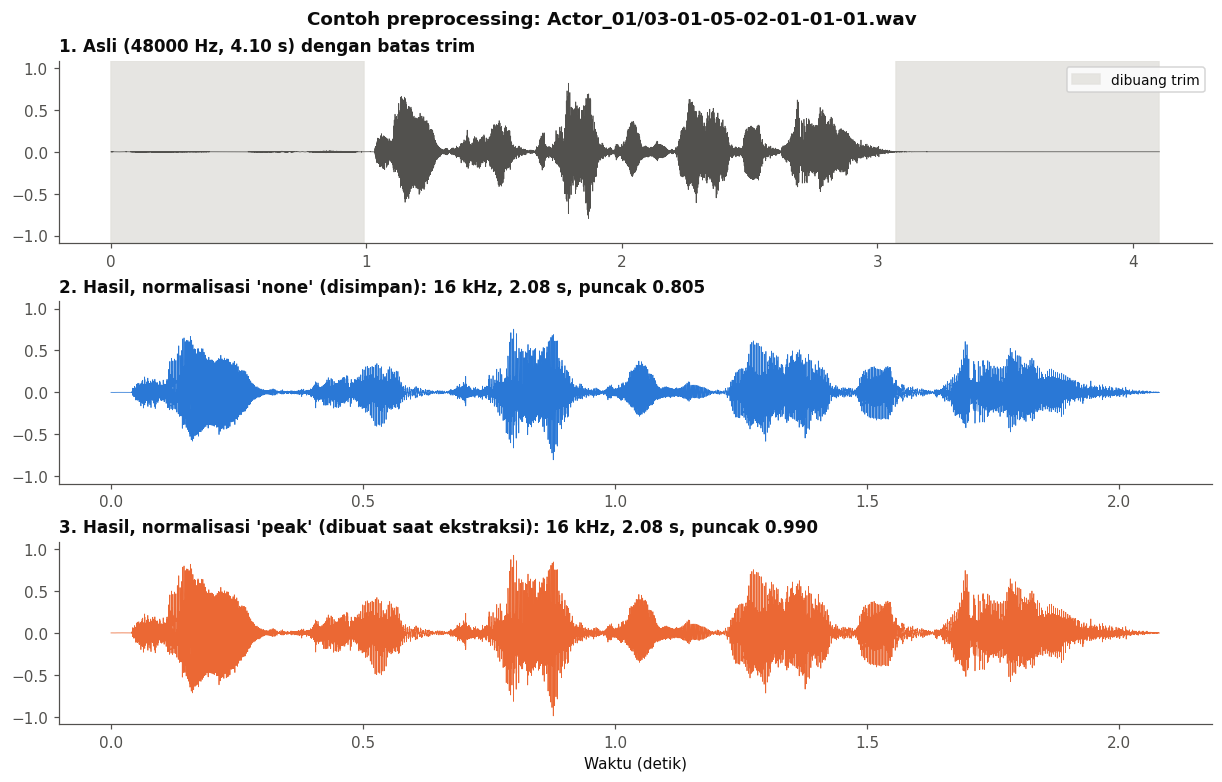

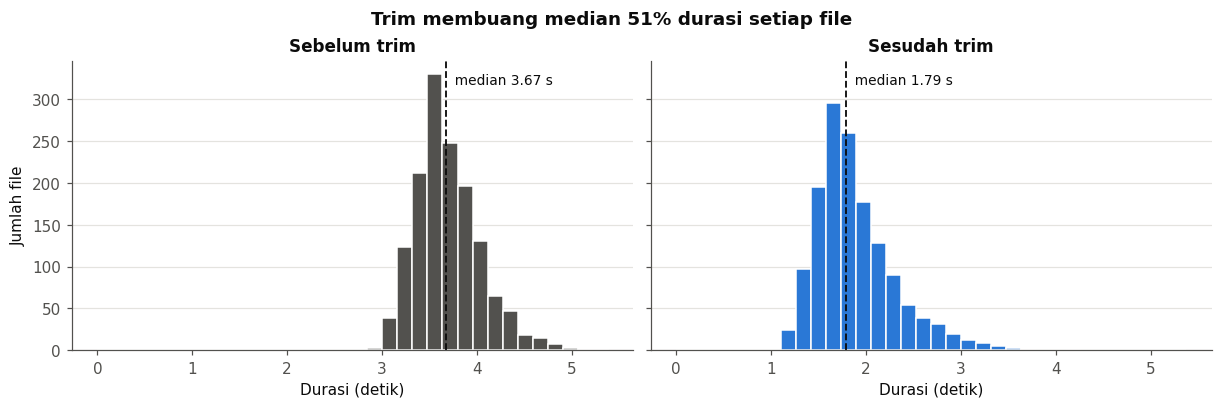

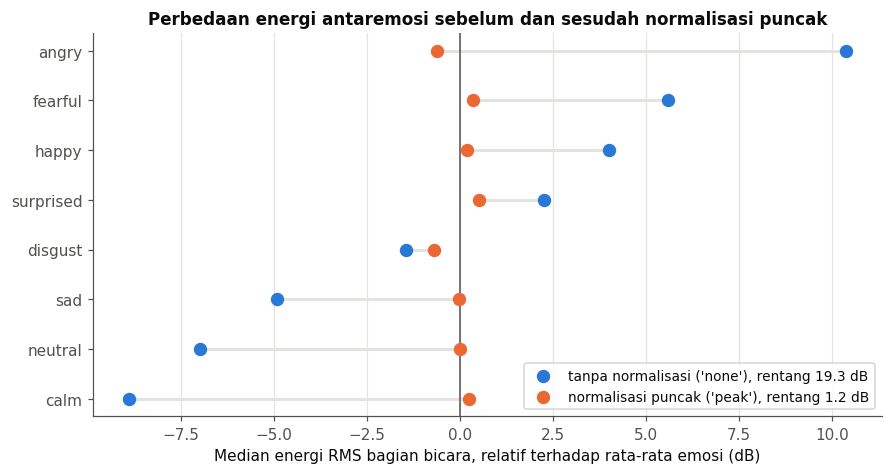

,rentang antaremosi (dB),rentang antaraktor (dB)
none,19.3,18.5
peak,1.2,4.5


In [8]:
FILE_CONTOH = 'Actor_01/03-01-05-02-01-01-01.wav'  # aktor 1, angry, strong
if FILE_CONTOH not in set(log['file']):
    FILE_CONTOH = log['file'].iloc[0]
r = log.set_index('file').loc[FILE_CONTOH]
sr = PREPROCESS_CONFIG['target_sr']

y_asli, sr_asli = librosa.load(os.path.join(RAW_DIR, FILE_CONTOH), sr=None, mono=True)
y_none, _ = sf.read(os.path.join(PROC_DIR, FILE_CONTOH), dtype='float32')
y_peak = pp.normalize(y_none, 'peak', PREPROCESS_CONFIG['peak_target'])

fig, axes = plt.subplots(3, 1, figsize=(11, 7), layout='constrained')
t_asli = np.arange(len(y_asli)) / sr_asli
axes[0].plot(t_asli, y_asli, color=TEKS2, linewidth=0.5)
axes[0].axvspan(0, r['trim_start_s'], color=GRID, alpha=0.9, label='dibuang trim')
axes[0].axvspan(r['trim_end_s'], t_asli[-1], color=GRID, alpha=0.9)
axes[0].set_title(f'1. Asli ({sr_asli} Hz, {len(y_asli) / sr_asli:.2f} s) dengan batas trim', loc='left')
axes[0].legend(loc='upper right', fontsize=9)
for ax, y_, judul, warna in [(axes[1], y_none, "2. Hasil, normalisasi 'none' (disimpan)", BIRU),
                              (axes[2], y_peak, "3. Hasil, normalisasi 'peak' (dibuat saat ekstraksi)", ORANYE)]:
    ax.plot(np.arange(len(y_)) / sr, y_, color=warna, linewidth=0.5)
    ax.set_title(f'{judul}: 16 kHz, {len(y_) / sr:.2f} s, puncak {np.max(np.abs(y_)):.3f}', loc='left')
ylim = max(np.max(np.abs(y_peak)), np.max(np.abs(y_asli))) * 1.1
for ax in axes:
    ax.set_ylim(-ylim, ylim)
    ax.grid(False)
axes[-1].set_xlabel('Waktu (detik)')
fig.suptitle(f'Contoh preprocessing: {FILE_CONTOH}', fontweight='bold')
fig.savefig(os.path.join(FIG_DIR, 'pre_01_sebelum_sesudah.png'))
plt.show()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True, layout='constrained')
bins = np.linspace(0, log['orig_duration_s'].max() * 1.02, 35)
for ax, kol, judul, warna in [(a1, 'orig_duration_s', 'Sebelum trim', TEKS2), (a2, 'proc_duration_s', 'Sesudah trim', BIRU)]:
    ax.hist(log[kol], bins=bins, color=warna, edgecolor='white')
    ax.axvline(log[kol].median(), color=TEKS, linestyle='--', linewidth=1.2)
    ax.text(log[kol].median(), ax.get_ylim()[1] * 0.92, f'  median {log[kol].median():.2f} s', fontsize=9)
    ax.set_title(judul)
    ax.set_xlabel('Durasi (detik)')
    ax.grid(axis='x', visible=False)
a1.set_ylabel('Jumlah file')
fig.suptitle(f"Trim membuang median {log['removed_ratio'].median() * 100:.0f}% durasi setiap file", fontweight='bold')
fig.savefig(os.path.join(FIG_DIR, 'pre_02_durasi.png'))
plt.show()

log['rms_peak_db'] = log['rms_trim_db'] + log['peak_gain_db']
med = log.groupby('emotion')[['rms_trim_db', 'rms_peak_db']].median().reindex(EMOSI)
rel = med - med.mean()   # relatif terhadap rata-rata 8 emosi, supaya kedua versi bisa dibandingkan di sumbu yang sama
urut = rel.sort_values('rms_trim_db').index.tolist()
r_none = med['rms_trim_db'].max() - med['rms_trim_db'].min()
r_peak = med['rms_peak_db'].max() - med['rms_peak_db'].min()
fig, ax = plt.subplots(figsize=(8, 4.2), layout='constrained')
yy = np.arange(len(urut))
ax.hlines(yy, rel.loc[urut, 'rms_peak_db'], rel.loc[urut, 'rms_trim_db'], color=GRID, linewidth=2, zorder=1)
ax.scatter(rel.loc[urut, 'rms_trim_db'], yy, color=BIRU, s=60, zorder=3, label=f"tanpa normalisasi ('none'), rentang {r_none:.1f} dB")
ax.scatter(rel.loc[urut, 'rms_peak_db'], yy, color=ORANYE, s=60, zorder=3, label=f"normalisasi puncak ('peak'), rentang {r_peak:.1f} dB")
ax.axvline(0, color=TEKS2, linewidth=1)
ax.set_yticks(yy, urut)
ax.set_xlabel('Median energi RMS bagian bicara, relatif terhadap rata-rata emosi (dB)')
ax.legend(loc='lower right', frameon=True, fontsize=9)
ax.grid(axis='y', visible=False)
ax.set_title('Perbedaan energi antaremosi sebelum dan sesudah normalisasi puncak')
fig.savefig(os.path.join(FIG_DIR, 'pre_03_energi_none_vs_peak.png'))
plt.show()

per_aktor = log.groupby('actor')[['rms_trim_db', 'rms_peak_db']].median()
ringkas_energi = pd.DataFrame({
    'rentang antaremosi (dB)': [med['rms_trim_db'].max() - med['rms_trim_db'].min(), med['rms_peak_db'].max() - med['rms_peak_db'].min()],
    'rentang antaraktor (dB)': [per_aktor['rms_trim_db'].max() - per_aktor['rms_trim_db'].min(), per_aktor['rms_peak_db'].max() - per_aktor['rms_peak_db'].min()],
}, index=['none', 'peak']).round(1)
display(ringkas_energi)

**Cara membaca grafik 3 dan tabel di bawahnya**

- **Rentang antaremosi** = selisih energi emosi terkeras dan terpelan. Semakin besar, semakin berguna energi untuk membedakan emosi.
- **Rentang antaraktor** = selisih energi aktor terkeras dan terpelan. Semakin besar, semakin besar pengaruh "siapa yang berbicara" terhadap energi, yang tidak diinginkan.
- Normalisasi yang ideal mengecilkan rentang antaraktor tanpa banyak mengecilkan rentang antaremosi. Angka-angka ini dikirim ke Anggota B sebagai bahan keputusan, bersama hasil baseline nanti.

## Sel 8 — Ringkasan dan dokumentasi standar

Sel ini menyimpan dua file:

1. `figures/preprocess/preprocess_summary.txt` — angka-angka kunci dan hasil verifikasi.
2. `docs/README_langkah4_preprocessing.md` — **dokumentasi standar** langkah 4: tujuan, input, output, parameter, cara menjalankan, cara memakai modul, verifikasi, keputusan, dan keterbatasan. File ini ditujukan untuk anggota kelompok lain dan sebagai lampiran repositori.

In [9]:
tgl = datetime.now().strftime('%Y-%m-%d')
n_ok = sum(t.startswith('[OK') for t in laporan)
L = log
ringkas = [
    f'Ringkasan preprocessing RAVDESS speech (langkah 4, {tgl})',
    f'Parameter: {json.dumps(PREPROCESS_CONFIG)}',
    f'config_hash: {CONFIG_HASH}',
    '',
    f'File diproses: {len(L)}',
    f"Durasi sebelum trim: median {L['orig_duration_s'].median():.2f} s ({L['orig_duration_s'].min():.2f}-{L['orig_duration_s'].max():.2f} s)",
    f"Durasi sesudah trim: median {L['proc_duration_s'].median():.2f} s ({L['proc_duration_s'].min():.2f}-{L['proc_duration_s'].max():.2f} s)",
    f"Proporsi dibuang: median {L['removed_ratio'].median() * 100:.0f}%",
    f"Total durasi: {L['orig_duration_s'].sum() / 60:.1f} menit -> {L['proc_duration_s'].sum() / 60:.1f} menit",
    f"Puncak setelah trim: median {L['peak_trim'].median():.3f}; >= 0,99: {int((L['peak_trim'] >= 0.99).sum())} file",
    f"Faktor normalisasi puncak: {L['peak_gain_db'].min():.1f} sampai {L['peak_gain_db'].max():.1f} dB (median {L['peak_gain_db'].median():.1f} dB)",
    '',
    'Energi (median per emosi / per aktor):',
    f"  none : rentang antaremosi {ringkas_energi.loc['none', 'rentang antaremosi (dB)']} dB, antaraktor {ringkas_energi.loc['none', 'rentang antaraktor (dB)']} dB",
    f"  peak : rentang antaremosi {ringkas_energi.loc['peak', 'rentang antaremosi (dB)']} dB, antaraktor {ringkas_energi.loc['peak', 'rentang antaraktor (dB)']} dB",
    '',
    f'Verifikasi: {n_ok}/{len(laporan)} OK',
] + ['  ' + t for t in laporan]
teks = '\n'.join(ringkas)
print(teks)
with open(os.path.join(FIG_DIR, 'preprocess_summary.txt'), 'w', encoding='utf-8') as f:
    f.write(teks + '\n')

readme = f'''# Langkah 4 — Preprocessing Audio RAVDESS

Penanggung jawab: Anggota A · Versi modul: {pp.PREPROCESS_VERSION} · Dijalankan: {tgl} · config_hash: `{CONFIG_HASH}`

## Tujuan

Menyiapkan 1.440 rekaman RAVDESS speech agar siap diekstrak fiturnya, dengan aturan yang sama untuk semua file dan bisa diulang persis.

## Urutan proses

1. Muat audio dan ubah ke mono (rata-rata channel; termasuk 5 file stereo yang kedua channel-nya identik)
2. Resample 48 kHz -> {PREPROCESS_CONFIG['target_sr']} Hz
3. Trim hening awal dan akhir: `top_db={PREPROCESS_CONFIG['trim_top_db']}`, `frame_length={PREPROCESS_CONFIG['trim_frame_length']}`, `hop_length={PREPROCESS_CONFIG['trim_hop_length']}`
4. Normalisasi amplitudo (pilihan): `'none'` atau `'peak'` (puncak -> {PREPROCESS_CONFIG['peak_target']})

## Input

| File | Asal |
| --- | --- |
| `data/metadata.csv` | Langkah 1 |
| `data/raw/ravdess_speech/` | Audio asli dari Zenodo (tidak diubah) |
| `data/eda_audio_stats.csv` | Langkah 3 (hanya untuk verifikasi) |

## Output

| File | Isi |
| --- | --- |
| `src/preprocess.py` | Modul preprocessing (sumber tunggal aturan preprocessing) |
| `config.json` -> `preprocessing` | Parameter, versi, config_hash |
| `data/processed/ravdess_16k_trim/Actor_XX/*.wav` | {len(L)} WAV mono {PREPROCESS_CONFIG['target_sr']} Hz, float32, sudah trim, **tanpa normalisasi** |
| `data/preprocess_log.csv` | Per file: durasi asli, batas trim, durasi hasil, proporsi dibuang, puncak, energi, faktor normalisasi |
| `figures/preprocess/` | `pre_01_sebelum_sesudah.png`, `pre_02_durasi.png`, `pre_03_energi_none_vs_peak.png`, `preprocess_summary.txt` |

## Cara menjalankan ulang

Buka `notebooks/Langkah4_AnggotaA_Preprocessing.ipynb` di Colab dan jalankan semua sel berurutan. Jika parameter di Sel 2 tidak berubah, pemrosesan dilewati dan log dimuat.

## Cara memakai modul (untuk langkah 5 dan demo)

```python
import sys
sys.path.insert(0, '/content/drive/MyDrive/project07/src')
import preprocess as pp
import soundfile as sf

# a) Audio yang sudah diproses (langkah 5): tinggal pilih normalisasi
y, sr = sf.read('.../data/processed/ravdess_16k_trim/Actor_01/03-01-05-02-01-01-01.wav', dtype='float32')
y_peak = pp.normalize(y, 'peak', 0.99)

# b) File mentah atau rekaman baru (demo): seluruh preprocessing sekaligus
y, sr, info = pp.preprocess_file('rekaman.wav', normalize_method='none')
```

## Verifikasi

{n_ok}/{len(laporan)} pemeriksaan OK.

''' + '\n'.join(f'- {t}' for t in laporan) + f'''

## Keputusan dan alasannya

| Keputusan | Alasan |
| --- | --- |
| Audio terproses disimpan satu versi (tanpa normalisasi) | Batas trim tidak berubah saat volume diubah (terbukti di Sel 4), jadi normalisasi puncak cukup dilakukan saat ekstraksi fitur |
| Normalisasi dibandingkan, bukan langsung dipilih | EDA: energi membedakan emosi (selisih ±19 dB) tetapi juga berbeda antaraktor (±18 dB). Fitur diekstrak dua versi; Anggota B memilih berdasarkan macro F1 validation |
| Format float32 | Nilai di atas 1,0 pada 18 file clipping tidak terpotong lagi saat disimpan |
| Semua file dipertahankan | File clipping adalah angry/fearful strong (sifat emosi); 53 file dengan hening hampir nol tetap berisi ucapan utuh |
| Parameter trim sama dengan EDA | Hasil preprocessing bisa dicocokkan dengan analisis langkah 3 |

## Keterbatasan

- Pada 53 file (3,7%; tidak ada di data test) trim tidak membuang bunyi kecil bukan-ucapan di tepi file (klik, noise, dengung), sehingga fitur file tersebut sedikit tercampur.
- Ambang trim relatif terhadap puncak file, sehingga pada rekaman sangat pelan noise latar lebih mudah ikut tersisa.
- Resampling ke 16 kHz membuang frekuensi di atas 8 kHz.

## Riwayat versi

| Versi | Tanggal | Perubahan |
| --- | --- | --- |
| 1.0 | {tgl} | Versi pertama |
'''
readme_path = os.path.join(DOC_DIR, 'README_langkah4_preprocessing.md')
with open(readme_path, 'w', encoding='utf-8') as f:
    f.write(readme)
print('\nTersimpan:', os.path.join(FIG_DIR, 'preprocess_summary.txt'))
print('Tersimpan:', readme_path)

Ringkasan preprocessing RAVDESS speech (langkah 4, 2026-11-21)
Parameter: {"target_sr": 16000, "mono": true, "trim_top_db": 30, "trim_frame_length": 2048, "trim_hop_length": 512, "peak_target": 0.99}
config_hash: d930ff28cd

File diproses: 1440
Durasi sebelum trim: median 3.67 s (2.94-5.27 s)
Durasi sesudah trim: median 1.79 s (1.15-4.25 s)
Proporsi dibuang: median 51%
Total durasi: 88.8 menit -> 45.5 menit
Puncak setelah trim: median 0.097; >= 0,99: 18 file
Faktor normalisasi puncak: -0.5 sampai 46.8 dB (median 20.2 dB)

Energi (median per emosi / per aktor):
  none : rentang antaremosi 19.3 dB, antaraktor 18.5 dB
  peak : rentang antaremosi 1.2 dB, antaraktor 4.5 dB

Verifikasi: 8/8 OK
  [OK ] Jumlah baris log = jumlah file metadata — 1440 / 1440
  [OK ] Semua file hasil ada — 1440 file
  [OK ] Format 16 kHz, mono, float32 (30 file acak)
  [OK ] Tidak ada NaN / tak hingga (30 file acak)
  [OK ] Durasi terpendek setelah trim >= 0,5 s — 1.15 s
  [OK ] Durasi hasil = durasi bicara EDA —

## Selesai — yang dilakukan setelah notebook ini

1. Pastikan semua uji di Sel 4 dan verifikasi di Sel 6 bertanda **OK**.
2. Simpan notebook ini ke `project07/notebooks/Langkah4_AnggotaA_Preprocessing.ipynb`.
3. Kirim untuk dicatat di Log Kerja:
   - isi `figures/preprocess/preprocess_summary.txt`
   - screenshot grafik Sel 7 (terutama grafik 3) dan tabel rentang energi
4. Beri tahu **Anggota B**: tabel rentang energi `none` vs `peak` sebagai bahan keputusan normalisasi, dan bahwa parameter preprocessing ada di `config.json`.
5. Beri tahu **Anggota C**: modul `src/preprocess.py` siap dipakai untuk demo (lihat bagian "Cara memakai modul" di README).